<hr>

<div align="center">

<h1>
Housing Affordability Dynamics:<br>
Price-to-Rent Ratios Across U.S. Metro Areas, 2020-August 2026
</h1>

<h3>
DATA 400 Individual Mini-Project · Fall 2026 · Thao Nguyen
</h3>

</div>

<hr>

## 1. Introduction

This project examines how the relationship between home values and rents changed across the 100 largest U.S. metropolitan areas from January 2020 through August 2026.

The main research question is:

> **How did home values change relative to rents across the 100 largest U.S. metropolitan areas from January 2020 through August 2026, and which metros experienced the largest differences between home-price growth and rent growth?**

Home prices and rents are not directly equivalent: a home price is the value of an asset, while rent is a recurring housing expense. Therefore, this project does **not** compare a home's purchase price with one month's rent as if they were the same type of cost. Instead, it examines their relationship using two complementary approaches:

- **Price-to-rent ratio (PTR):** home value divided by annualized rent. This expresses a home's value relative to a year's rent and helps show whether home values are rising or falling relative to rents.
- **Indexed trends and growth rates:** home values and rents are each set to an index of 100 at the beginning of the study period. Comparing their percentage changes makes it possible to see which has grown faster, without treating their different dollar scales as directly comparable.

These measures describe market trends, not the full financial cost of owning versus renting. Mortgage interest, taxes, insurance, maintenance, down payments, and investment returns are not included. The analysis uses Zillow's **Home Value Index (ZHVI)** and **Observed Rent Index (ZORI)** to study changes over time and differences across metropolitan areas.

---

## 2. Data Sources

The analysis uses two Zillow Research datasets:

- **Zillow Home Value Index (ZHVI)** – measures typical home values.
- **Zillow Observed Rent Index (ZORI)** – measures typical observed rents.

The datasets contain monthly observations for U.S. metropolitan areas.

For this project, I focus on:

- The **100 largest metropolitan areas** based on Zillow's `SizeRank`
- January 2020 through August 2026
- Metropolitan areas that have sufficient coverage in both datasets

---


## 3. Data Preparation
---

In [1]:
# Import libraries for data analysis, visualization, and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import tools for standardizing data and performing K-means clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
from pathlib import Path

# Set the data directory relative to the project root
DATA_DIR = Path("Data")

# Load datasets
zhvi_raw = pd.read_csv(DATA_DIR / "Metro_zhvi.csv")
zori_raw = pd.read_csv(DATA_DIR / "Metro_zori.csv")

# Check dataset dimensions
print("ZHVI shape:", zhvi_raw.shape)
print("ZORI shape:", zori_raw.shape)

ZHVI shape: (895, 325)
ZORI shape: (750, 145)


In [3]:
# Display the first five rows of the ZHVI dataset
zhvi_raw.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,1/31/2000,2/29/2000,3/31/2000,4/30/2000,5/31/2000,...,11/30/2025,12/31/2025,1/31/2026,2/28/2026,3/31/2026,4/30/2026,5/31/2026,6/30/2026,7/31/2026,8/31/2026
0,102001,0,United States,country,NaN,123577.7596,123795.1725,124064.7965,124643.0871,125308.6302,...,365789.6372,366588.3871,367350.4469,368071.7143,368567.1729,368647.3330,368385.2914,368141.6470,368249.9967,368696.6847
1,394913,1,"New York, NY",msa,NY,220013.1236,220948.0553,221891.6461,223803.7261,225783.7513,...,708946.1759,712394.8245,715484.0295,719086.8624,722906.4551,725334.9455,726872.5619,728366.5978,731367.8023,735075.4727
2,753899,2,"Los Angeles, CA",msa,CA,221912.2698,222738.0650,223838.0163,226026.5500,228420.1197,...,948164.0844,952130.0482,954663.8971,955897.6374,955563.2371,953938.7202,952480.4871,950999.8555,951215.3473,952601.2482
3,394463,3,"Chicago, IL",msa,IL,156387.2539,156532.0229,156807.7381,157493.6490,158318.7173,...,344798.3611,346563.9567,348215.0633,349995.1823,351427.8526,352446.0177,353069.5214,353938.4329,355375.9316,357264.9354
4,394514,4,"Dallas, TX",msa,TX,129720.8578,129778.6360,129845.0578,130017.5484,130244.9726,...,367550.9885,367329.7124,366889.0939,366304.4825,365232.4178,363899.1484,362320.8086,361073.9506,360453.4980,360436.8173


**Selecting the 100 Largest Metropolitan Areas**

To focus the analysis on the largest U.S. metropolitan areas, I select observations classified as metropolitan statistical areas (MSAs) and rank them using Zillow's `SizeRank`. I then keep the 100 largest metropolitan areas for the analysis.

In [4]:
# Keep only metropolitan areas (MSAs) from the ZHVI dataset
msa = zhvi_raw[zhvi_raw["RegionType"] == "msa"]
# Sort metropolitan areas by Zillow's SizeRank
msa = msa.sort_values("SizeRank")
# Select the 100 largest metropolitan areas
top100 = msa.head(100)
# Keep only the columns needed to identify the selected metros
top100 = top100[["RegionID", "RegionName", "SizeRank"]]
# Display the first five selected metropolitan areas
top100.head()
# Check the number of metropolitan areas selected
print("Number of metros:", len(top100))

Number of metros: 100


In [5]:
# Check which selected metros are also available in the ZORI dataset
top100["RegionID"].isin(zori_raw["RegionID"]).value_counts()
# Keep only metros that appear in both the ZHVI and ZORI datasets
top100 = top100[top100["RegionID"].isin(zori_raw["RegionID"])]
# Check how many metros are available in both datasets
print("Metros available in both datasets:", len(top100))

Metros available in both datasets: 100


**Reshaping the Data into Monthly Format**

The ZHVI and ZORI datasets are originally in wide format, with each month represented as a separate column. I reshape both datasets into long format so that each observation represents one metro-month combination.

The final panel dataset contains:

- `RegionID`
- `date`
- `zhvi`
- `zori`
- `RegionName`
- `SizeRank`

The datasets are then merged using `RegionID` and `date`.

In [6]:
# The raw files have one column per month. I want one row for each metro-month observation instead.
id_cols = ["RegionID", "SizeRank", "RegionName", "RegionType", "StateName"]
start_date = pd.to_datetime("2020-01-01")
# Keep only the monthly columns from January 2020 onward
zhvi_months = [c for c in zhvi_raw.columns if c not in id_cols and pd.to_datetime(c) >= start_date]
zori_months = [c for c in zori_raw.columns if c not in id_cols and pd.to_datetime(c) >= start_date]
# Keep only the selected 100 metropolitan areas
zhvi_small = zhvi_raw[zhvi_raw["RegionID"].isin(top100["RegionID"])]
zori_small = zori_raw[zori_raw["RegionID"].isin(top100["RegionID"])]
# Convert the ZHVI data from wide format to long format
zhvi_long = zhvi_small.melt(
    id_vars="RegionID",
    value_vars=zhvi_months,
    var_name="date",
    value_name="zhvi"
)
# Convert the ZORI data from wide format to long format
zori_long = zori_small.melt(
    id_vars="RegionID",
    value_vars=zori_months,
    var_name="date",
    value_name="zori"
)
# Convert the date column from text to a datetime format
zhvi_long["date"] = pd.to_datetime(zhvi_long["date"])
zori_long["date"] = pd.to_datetime(zori_long["date"])
# Display the first five rows of the reshaped ZHVI dataset
zhvi_long.head()

,RegionID,date,zhvi
0,394913,2020-01-31,509099.7808
1,753899,2020-01-31,669786.0585
2,394463,2020-01-31,243955.2853
3,394514,2020-01-31,263767.5968
4,394692,2020-01-31,230309.7261


In [7]:
# Merge the ZHVI and ZORI datasets using metro ID and date
panel = pd.merge(
    zhvi_long,
    zori_long,
    on=["RegionID", "date"]
)
# Display the first five rows of the merged dataset
panel.head()

,RegionID,date,zhvi,zori
0,394913,2020-01-31,509099.7808,2583.127446
1,753899,2020-01-31,669786.0585,2266.695281
2,394463,2020-01-31,243955.2853,1548.867426
3,394514,2020-01-31,263767.5968,1294.811095
4,394692,2020-01-31,230309.7261,1338.696973


**Filter the Dataset to the Top 100 Metropolitan Areas**

Merge the housing panel dataset with `top100` using `RegionID` as the common key. This keeps only observations corresponding to the 100 largest metropolitan areas identified in `top100`, restricting the analysis to the project's target sample.

In [8]:
# Keep only observations from the top 100 metropolitan areas
panel = pd.merge(
    panel,
    top100,
    on="RegionID"
)
panel.head()

,RegionID,date,zhvi,zori,RegionName,SizeRank
0,394913,2020-01-31,509099.7808,2583.127446,"New York, NY",1
1,753899,2020-01-31,669786.0585,2266.695281,"Los Angeles, CA",2
2,394463,2020-01-31,243955.2853,1548.867426,"Chicago, IL",3
3,394514,2020-01-31,263767.5968,1294.811095,"Dallas, TX",4
4,394692,2020-01-31,230309.7261,1338.696973,"Houston, TX",5


In [9]:
# Sort observations by metropolitan area and date
panel = panel.sort_values(
    ["RegionID", "date"]
).reset_index(drop=True)
# Check the dataset dimensions and preview the first five rows
print(panel.shape)
panel.head()

(8000, 6)


,RegionID,date,zhvi,zori,RegionName,SizeRank
0,394304,2020-01-31,155030.0159,839.603399,"Akron, OH",83
1,394304,2020-02-29,155936.5827,840.365569,"Akron, OH",83
2,394304,2020-03-31,157046.2056,850.081798,"Akron, OH",83
3,394304,2020-04-30,158193.8254,858.997292,"Akron, OH",83
4,394304,2020-05-31,158833.7624,872.556193,"Akron, OH",83


In [10]:
# Count missing values in home value and rent indices
print("Missing values:")
print(panel[["zhvi", "zori"]].isna().sum())

Missing values:
zhvi    2
zori    0
dtype: int64


In [11]:
# Count the number of monthly observations for each metro area
months = panel.groupby("RegionName")["date"].count()
# Summarize data coverage across metropolitan areas
print(months.describe())

count    100.0
mean      80.0
std        0.0
min       80.0
25%       80.0
50%       80.0
75%       80.0
max       80.0
Name: date, dtype: float64


**Filter Metropolitan Areas by Data Coverage**

Retain only metropolitan areas with at least 95% of the expected monthly observations during the study period. From January 2020 through August 2026, there are 80 expected months, so each metro must have at least 76 observations to be included. This filtering step helps ensure sufficient time-series coverage for comparing home values and rents while reducing the influence of incomplete data.

In [12]:
# Set the minimum required observations (95% of 80 months)
minimum_months = 80 * 0.95
# Identify metros meeting the data coverage requirement
good_metros = months[months >= minimum_months].index
# Keep only observations from metros with sufficient data coverage
panel = panel[panel["RegionName"].isin(good_metros)]

**Handle Missing Values**

Remove observations with missing values in either the `zhvi` or `zori` column. Both variables are required to calculate the price-to-rent ratio and compare home-price and rent trends. After removing incomplete observations, check the remaining missing-value counts to verify the cleaning step.

In [13]:
# Remove rows with missing home value or rent data
panel = panel.dropna(subset=["zhvi", "zori"])
# Verify that no missing values remain in these columns
print("Missing values after cleaning:")
print(panel[["zhvi", "zori"]].isna().sum())

Missing values after cleaning:
zhvi    0
zori    0
dtype: int64


In [14]:
# Check the number of metropolitan areas and unique months
print("Number of metros:", panel["RegionName"].nunique())
print("Number of months:", panel["date"].nunique())
# Check the temporal coverage of the dataset
print("Date range:", panel["date"].min(), "to", panel["date"].max())

Number of metros: 100
Number of months: 80
Date range: 2020-01-31 00:00:00 to 2026-08-31 00:00:00


## 4. Feature Engineering
---

**Calculate Annualized Rent**

Convert monthly rent into an annual amount by multiplying the zori value by 12. This creates the annual_rent variable, which allows rent to be compared with home values when calculating the price-to-rent ratio (PTR). Annualizing rent provides a consistent time basis for examining the relationship between home prices and rental costs.

In [15]:
# Convert monthly rent into annual rent
panel["annual_rent"] = panel["zori"] * 12

**Calculate the Price-to-Rent Ratio (PTR)**

Calculate the price-to-rent ratio by dividing the Zillow Home Value Index (`zhvi`) by annualized rent (`annual_rent`). This metric measures the relationship between home values and annual rental costs across metropolitan areas over time. A higher PTR indicates that home values are relatively high compared with annual rents, while a lower PTR indicates that home values are relatively low compared with annual rents.

PTR is used to examine housing market dynamics, not to determine definitively whether buying or renting is financially better.

In [16]:
# Calculate the price-to-rent ratio
panel["ptr"] = panel["zhvi"] / panel["annual_rent"]

In [17]:
# Preview the original and newly engineered variables
panel[
    [
        "RegionName",
        "date",
        "zhvi",
        "zori",
        "annual_rent",
        "ptr"
    ]
].head()

,RegionName,date,zhvi,zori,annual_rent,ptr
0,"Akron, OH",2020-01-31,155030.0159,839.603399,10075.240788,15.387227
1,"Akron, OH",2020-02-29,155936.5827,840.365569,10084.386833,15.463169
2,"Akron, OH",2020-03-31,157046.2056,850.081798,10200.981580,15.395205
3,"Akron, OH",2020-04-30,158193.8254,858.997292,10307.967503,15.346752
4,"Akron, OH",2020-05-31,158833.7624,872.556193,10470.674320,15.169392


**How to interpret the price-to-rent ratio**

The PTR is not a claim that buying a home and renting a home have the same upfront cost. It compares a home's value with the rent it could generate over a year. For example, a PTR of 25 means the home value equals 25 times the current annual rent. A rising PTR means home values are increasing relative to rents; a falling PTR means rents are catching up with home values. This is a simplified market indicator, not a complete rent-versus-buy financial calculation.

In [18]:
# Summarize the distribution of the price-to-rent ratio
print(panel["ptr"].describe())

count    7998.000000
mean       18.612852
std         4.318474
min        11.655324
25%        15.628392
50%        17.495339
75%        20.232080
max        39.863583
Name: ptr, dtype: float64


In [19]:
# Display the 10 observations with the highest price-to-rent ratios
panel[
    ["RegionName", "date", "ptr"]
].sort_values(
    "ptr",
    ascending=False
).head(10)

,RegionName,date,ptr
6427,"San Jose, CA",2022-04-30,39.863583
6428,"San Jose, CA",2022-05-31,39.830448
6460,"San Jose, CA",2025-01-31,39.493171
6426,"San Jose, CA",2022-03-31,39.490366
6459,"San Jose, CA",2024-12-31,39.453454
6429,"San Jose, CA",2022-06-30,39.222138
6461,"San Jose, CA",2025-02-28,39.134262
6458,"San Jose, CA",2024-11-30,38.969018
6425,"San Jose, CA",2022-02-28,38.797934
6462,"San Jose, CA",2025-03-31,38.476618


In [20]:
# Identify the first and last dates in the study period
first_date = panel["date"].min()
last_date = panel["date"].max()
# Extract observations from the beginning of the study period
start = panel[
    panel["date"] == first_date
]
# Extract observations from the end of the study period
end = panel[
    panel["date"] == last_date
]

In [21]:
# Select metro identifiers and baseline housing indicators
summary = start[
    ["RegionID", "RegionName", "SizeRank", "zhvi", "zori", "ptr"]
]
# Rename housing indicators to identify baseline values
summary = summary.rename(
    columns={
        "zhvi": "zhvi_start",
        "zori": "zori_start",
        "ptr": "ptr_start"
    }
)

In [22]:
# Merge ending-period indicators with the baseline summary
summary = pd.merge(
    summary,
    end[
        ["RegionID", "zhvi", "zori", "ptr"]
    ],
    on="RegionID"
)
# Rename columns to identify ending-period values
summary = summary.rename(
    columns={
        "zhvi": "zhvi_end",
        "zori": "zori_end",
        "ptr": "ptr_end"
    }
)
summary.head()

,RegionID,RegionName,SizeRank,zhvi_start,zori_start,ptr_start,zhvi_end,zori_end,ptr_end
0,394304,"Akron, OH",83,155030.0159,839.603399,15.387227,242458.7366,1327.463264,15.220681
1,394308,"Albany, NY",64,243675.8613,1165.510439,17.422685,375357.6974,1681.981094,18.597003
2,394312,"Albuquerque, NM",62,215309.2438,976.078801,18.382160,349918.5659,1498.689943,19.456913
3,394318,"Allentown, PA",70,225275.6011,1225.827586,15.314525,365870.8360,1851.519753,16.467141
4,394347,"Atlanta, GA",9,252897.1228,1317.828626,15.992034,377428.3976,1852.985271,16.973889


**Calculate Cumulative Home-Price Growth**

Calculate the percentage change in home values for each metropolitan area between the beginning and end of the study period (January 2020–August 2026). This measure captures the cumulative growth in home values over the entire period, allowing comparisons of housing market trends across metropolitan areas.

A positive value indicates that home values increased, while a negative value indicates that home values decreased over the study period.

In [23]:
# Calculate cumulative home-price growth as a percentage
summary["price_growth"] = (
    (summary["zhvi_end"] / summary["zhvi_start"]) - 1
) * 100

**Calculate Cumulative Rent Growth**

Calculate the percentage change in the Zillow Observed Rent Index (`zori`) for each metropolitan area between the beginning and end of the study period (January 2020–August 2026). This measure captures cumulative rent growth over the study period and allows comparison with home-price growth to determine whether rents have increased faster or slower than home values across metropolitan areas.

A positive value indicates that rents increased, while a negative value indicates that rents decreased over the study period.

In [24]:
# Calculate cumulative rent growth as a percentage
summary["rent_growth"] = (
    (summary["zori_end"] / summary["zori_start"]) - 1
) * 100

**Calculate the Change in Price-to-Rent Ratio**

Calculate the absolute change in the price-to-rent (PTR) ratio for each metropolitan area between the beginning and end of the study period (January 2020–August 2026). This measure shows how the relationship between home values and annualized rents has changed over time.

A positive value indicates that the PTR ratio increased, meaning home values grew relative to annualized rents. A negative value indicates that the PTR ratio decreased, meaning rents grew relative to home values. A value near zero indicates little overall change in the ratio.

In [25]:
# Calculate the absolute change in the price-to-rent ratio
summary["ptr_change"] = (
    summary["ptr_end"] - summary["ptr_start"]
)

**Calculate Price–Rent Growth Divergence**

Calculate the divergence between cumulative home-price growth and cumulative rent growth for each metropolitan area from January 2020 to August 2026. This metric helps identify whether home values have increased faster or slower than rents over the study period.

- **Positive divergence:** Home prices grew faster than rents, suggesting that homes became more expensive relative to rents.
- **Negative divergence:** Rents grew faster than home prices, suggesting that home values became less expensive relative to rents.
- **Zero divergence:** Home prices and rents grew at the same percentage rate.

The divergence is measured in **percentage points**, not as a percentage change in the PTR ratio.

In [26]:
# Calculate the difference between cumulative price growth and rent growth
summary["divergence"] = (
    summary["price_growth"] -
    summary["rent_growth"]
)

In [27]:
# Preview growth and affordability metrics for the first 10 metros
summary[
    [
        "RegionName",
        "price_growth",
        "rent_growth",
        "ptr_change",
        "divergence"
    ]
].head(10)

,RegionName,price_growth,rent_growth,ptr_change,divergence
0,"Akron, OH",56.394705,58.105990,-0.166546,-1.711284
1,"Albany, NY",54.039754,44.312830,1.174318,9.726924
2,"Albuquerque, NM",62.519063,53.541901,1.074753,8.977162
3,"Allentown, PA",62.410325,51.042428,1.152616,11.367897
4,"Atlanta, GA",49.241871,40.608971,0.981855,8.632900
5,"Augusta, GA",52.174571,51.684808,0.045561,0.489763
6,"Austin, TX",26.328442,15.792858,1.790728,10.535584
7,"Bakersfield, CA",53.154363,56.611664,-0.382391,-3.457301
8,"Baltimore, MD",33.532747,34.472992,-0.120578,-0.940244
9,"Baton Rouge, LA",24.597626,28.082916,-0.419689,-3.485289


In [28]:
# Generate descriptive statistics for growth and affordability metrics
summary[
    [
        "price_growth",
        "rent_growth",
        "ptr_change",
        "divergence"
    ]
].describe()

,price_growth,rent_growth,ptr_change,divergence
count,100.000000,100.000000,100.000000,100.000000
mean,48.084987,42.347026,0.713562,5.737961
std,12.295963,10.344253,1.024757,7.925527
min,5.920429,15.792858,-3.053343,-23.764054
25%,40.798364,36.373792,0.042386,0.459251
50%,49.533671,43.011572,0.714809,5.758256
75%,54.527460,50.495250,1.395565,11.226737
max,79.921585,63.270160,3.369484,29.426783


## 5. Analysis and Visualization
---

**Analyze Annual Home Value and Rent Growth**

Aggregate home values (`zhvi`) and rents (`zori`) by calendar year using the median across the available observations. Then calculate year-over-year percentage growth for each metric.

Using the median helps reduce the influence of unusually high or low observations. The annual growth rates show how home values and rents change from one year to the next, allowing us to compare their trends over time.

**Note:** Because the data is grouped across all available metro-month observations within each year, these figures represent the median across the pooled observations, not the median of each metro's annual average. The first year's growth will be missing because there is no preceding year in the grouped data for comparison.

In [29]:
# Calculate yearly median home value and rent
annual = panel.groupby(panel["date"].dt.year)[["zhvi", "zori"]].median()

# Calculate year-over-year growth rates as percentages
annual["home_growth"] = annual["zhvi"].pct_change() * 100
annual["rent_growth"] = annual["zori"].pct_change() * 100

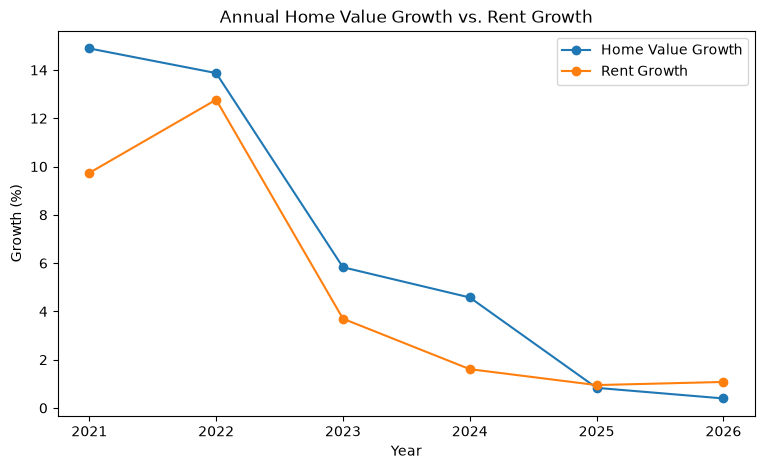

In [30]:
# Create a line chart comparing annual home value and rent growth
plt.figure(figsize=(9, 5))
plt.plot(
    annual.index,
    annual["home_growth"],
    marker="o",
    label="Home Value Growth"
)
plt.plot(
    annual.index,
    annual["rent_growth"],
    marker="o",
    label="Rent Growth"
)
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.title("Annual Home Value Growth vs. Rent Growth")
plt.legend()
plt.show()

**Interpretation of Annual Home Value Growth vs. Rent Growth**

The chart shows that both home value growth and rent growth generally slowed from 2021 to 2026. Home value growth was higher than rent growth from 2021 through 2024, with the largest gap appearing in 2023. This suggests that home values were increasing faster than rents during these years.

In 2025, the two growth rates converged at approximately 1%, indicating similar growth rates. By 2026, home value growth declined to below 0.5%, while rent growth remained slightly above 1%. Overall, the results suggest that home value and rent growth slowed considerably over the study period, with rent growth slightly exceeding home value growth in the most recent year shown.

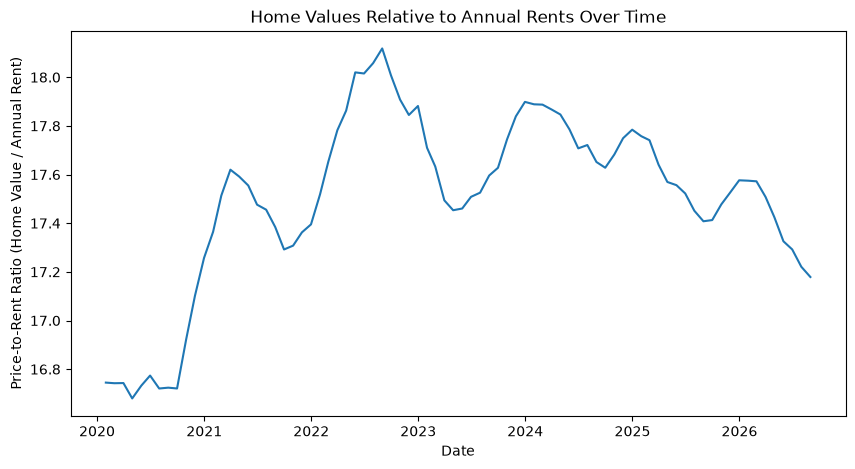

In [31]:
# Calculate the median price-to-rent (PTR) ratio across metropolitan areas for each month and visualize its trend throughout the study period.
ptr_by_month = panel.groupby("date")["ptr"].median()
plt.figure(figsize=(10, 5))
plt.plot(
    ptr_by_month.index,
    ptr_by_month.values
)
plt.title("Home Values Relative to Annual Rents Over Time")
plt.xlabel("Date")
plt.ylabel("Price-to-Rent Ratio (Home Value / Annual Rent)")
plt.show()

**Interpretation of Median Price-to-Rent Ratio Over Time**

The chart shows that the median price-to-rent (PTR) ratio increased from approximately 16.7 in early 2020 to a peak of around 18.1 in late 2022. This suggests that home values increased relative to annualized rents during this period.

From 2023 onward, the ratio fluctuated but generally trended downward, with a temporary increase in early 2024. By August 2026, the ratio had declined to approximately 17.2. This indicates that home values became less expensive relative to annualized rents compared with the peak in 2022, although the ratio remained above its early-2020 level.

Overall, the trend suggests that the relationship between home values and rents tightened during 2020–2022 and partially reversed afterward. However, the PTR ratio alone does not establish whether buying or renting is more affordable, as it excludes other costs associated with homeownership.

### Comparing relative changes instead of raw dollar amounts

Because home values and monthly rents have very different units and scales, this chart rebases both series to 100 at the start of the period. It compares **percentage growth from the same baseline**, not the dollar value of a home with one month's rent. If the home-value index rises faster than the rent index, home values have increased more rapidly over the period.

In [32]:
# Create an index where January 2020 = 100
panel["zhvi_index"] = (
    panel["zhvi"] /
    panel.groupby("RegionID")["zhvi"].transform("first")
) * 100

panel["zori_index"] = (
    panel["zori"] /
    panel.groupby("RegionID")["zori"].transform("first")
) * 100

In [33]:
# Calculate the monthly median of the home value and rent indices
index_by_month = panel.groupby("date")[
    ["zhvi_index", "zori_index"]
].median()

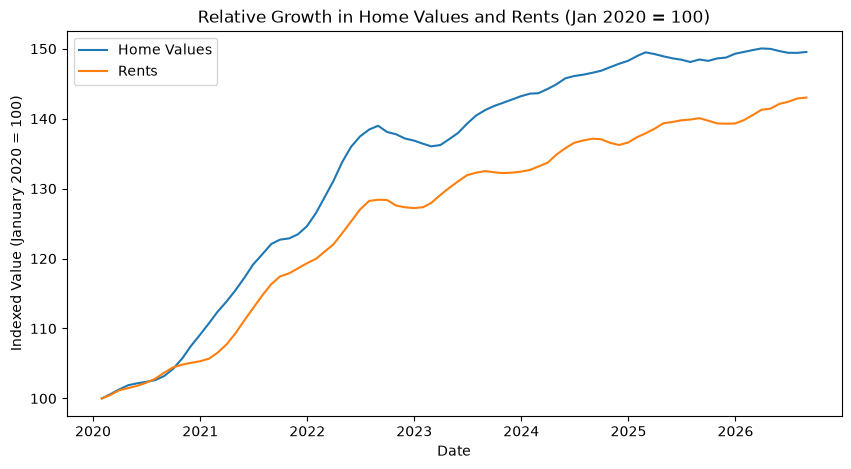

In [34]:
# Create a line chart comparing indexed home values and rents
plt.figure(figsize=(10, 5))
plt.plot(
    index_by_month.index,
    index_by_month["zhvi_index"],
    label="Home Values"
)
plt.plot(
    index_by_month.index,
    index_by_month["zori_index"],
    label="Rents"
)
plt.title("Relative Growth in Home Values and Rents (Jan 2020 = 100)")
plt.xlabel("Date")
plt.ylabel("Indexed Value (January 2020 = 100)")
plt.legend()
plt.show()

**Interpretation of Relative Growth in Home Values and Rents**

The chart shows that both home values and rents increased between January 2020 and August 2026, with home values generally growing faster than rents. Both indices started at 100 in January 2020. By August 2026, the home value index had risen to approximately 149, representing cumulative growth of about 49%, while the rent index reached approximately 143, representing growth of about 43%.

The gap between the two indices widened notably during 2021–2022, indicating that home values appreciated more rapidly than rents during this period. Although both indices continued to rise afterward, the gap remained relatively large through 2026.

Overall, the results suggest that home values experienced greater cumulative growth than rents over the study period. This indicates that homes became more expensive relative to their January 2020 baseline, although the indexed trends alone do not establish whether buying or renting is more affordable.

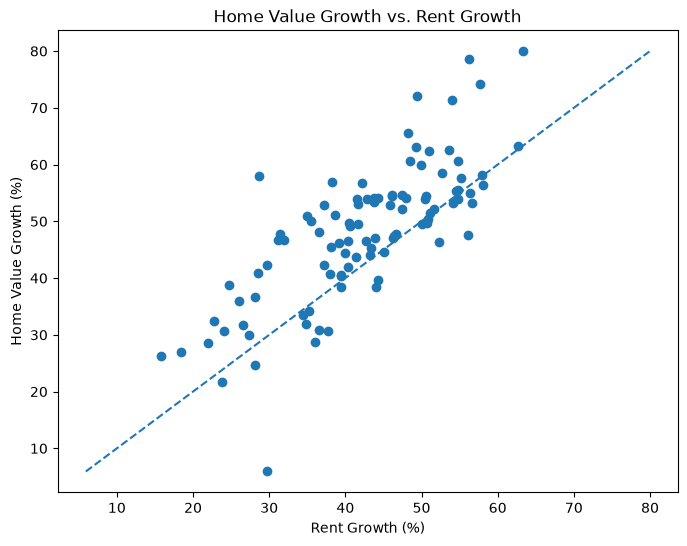

In [35]:
# Find the shared range for both axes
low = min(
    summary["rent_growth"].min(),
    summary["price_growth"].min()
)
high = max(
    summary["rent_growth"].max(),
    summary["price_growth"].max()
)
# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    summary["rent_growth"],
    summary["price_growth"]
)
plt.plot(
    [low, high],
    [low, high],
    "--"
)
plt.title("Home Value Growth vs. Rent Growth")
plt.xlabel("Rent Growth (%)")
plt.ylabel("Home Value Growth (%)")
plt.show()

**Interpretation of Home Value Growth vs. Rent Growth Across Metropolitan Areas**

The scatter plot shows a generally positive relationship between cumulative home value growth and rent growth across metropolitan areas from January 2020 to August 2026. Most metros experienced growth in both home values and rents, with rent growth ranging roughly from 20% to 60% and home value growth ranging from 30% to 60% for many observations.

Most points lie above the dashed diagonal line, indicating that home values grew faster than rents in many metropolitan areas. Several metros experienced particularly strong home value growth, exceeding 70%, while their rent growth was lower. However, some points fall below the line, showing that rents grew faster than home values in those markets.

Overall, the chart suggests that home value appreciation outpaced rent growth in many of the included metros, although the size and direction of the gap varied across locations. This highlights meaningful differences in housing market dynamics across metropolitan areas.

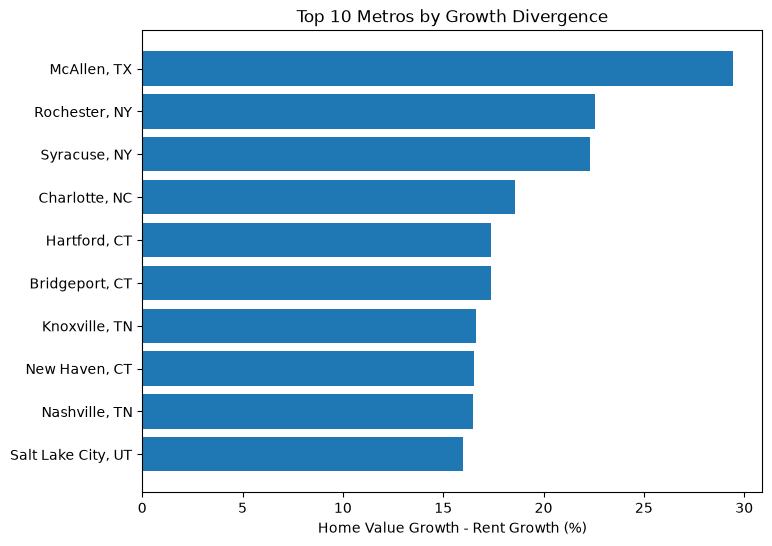

In [36]:
# Select the 10 metros with the highest growth divergence
top10 = summary.sort_values(
    "divergence",
    ascending=False
).head(10)

# Create a horizontal bar chart
plt.figure(figsize=(8, 6))
plt.barh(
    top10["RegionName"],
    top10["divergence"]
)
plt.title("Top 10 Metros by Growth Divergence")
plt.xlabel("Home Value Growth - Rent Growth (%)")
plt.gca().invert_yaxis()
plt.show()

**Interpretation of the Top 10 Metros by Growth Divergence**

The chart shows that McAllen, Texas, had the highest growth divergence, at approximately 29 percentage points, meaning home values grew substantially faster than rents between January 2020 and August 2026. Rochester and Syracuse, New York, followed with divergences of approximately 22–23 percentage points.

Charlotte, North Carolina, also showed a notable gap of about 18.5 percentage points, while several Connecticut metros including Hartford, Bridgeport, and New Haven—appeared among the top 10. Knoxville, Tennessee; Nashville, Tennessee; and Salt Lake City, Utah, also ranked highly, with divergences of roughly 16–17 percentage points.

Overall, these results indicate that home value growth outpaced rent growth considerably in these metropolitan areas. McAllen stands out as having the largest gap among the top 10, suggesting that home values appreciated particularly strongly relative to rents during the study period. However, growth divergence alone does not establish the overall affordability of housing in each metro, since it measures changes over time rather than current housing costs or household incomes.

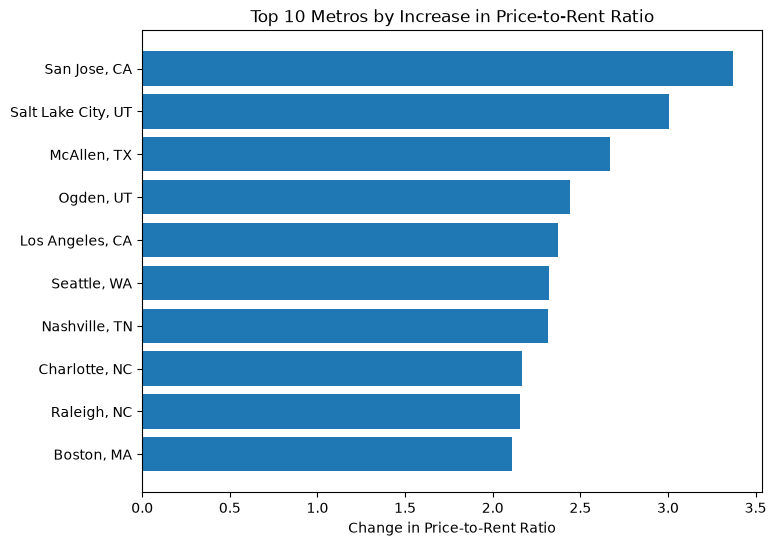

In [37]:
# Select the 10 metros with the largest increases in PTR
top10_ptr = summary.sort_values(
    "ptr_change",
    ascending=False
).head(10)
# Create a horizontal bar chart
plt.figure(figsize=(8, 6))
plt.barh(
    top10_ptr["RegionName"],
    top10_ptr["ptr_change"]
)
plt.title("Top 10 Metros by Increase in Price-to-Rent Ratio")
plt.xlabel("Change in Price-to-Rent Ratio")
plt.gca().invert_yaxis()

plt.show()

**Interpretation of the Top 10 Metros by Increase in Price-to-Rent Ratio**

The chart shows that San Jose, California, experienced the largest increase in the price-to-rent (PTR) ratio, rising by approximately 3.4 points between January 2020 and August 2026. Salt Lake City, Utah, ranked second with an increase of about 3.0 points, followed by McAllen, Texas, at approximately 2.7 points.

Other metros with substantial PTR increases included Ogden, Utah; Los Angeles, California; Seattle, Washington; Nashville, Tennessee; Charlotte, North Carolina; Raleigh, North Carolina; and Boston, Massachusetts. Their increases ranged from approximately 2.1 to 2.4 points.

Overall, these results suggest that home values increased relative to annualized rents in these metropolitan areas. San Jose stands out as having the largest shift in the relationship between home values and rents, while several metros in Utah, California, and the Southeast also experienced notable increases. These changes indicate that home values grew relative to rents, but do not by themselves establish which metros are least affordable, since the PTR ratio does not account for household incomes or other housing costs.

In [38]:
# Calculate year-over-year home value growth for each metro
panel["zhvi_yoy"] = (
    panel["zhvi"] /
    panel.groupby("RegionID")["zhvi"].shift(12)
    - 1
) * 100
# Calculate year-over-year rent growth for each metro
panel["zori_yoy"] = (
    panel["zori"] /
    panel.groupby("RegionID")["zori"].shift(12)
    - 1
) * 100

In [39]:
# Define time lags in months
lags = [0, 3, 6, 9, 12, 18, 24]
# Store correlation results for each lag
correlations = []
for lag in lags:
 # Match current rent growth with future home value growth
    future_price_growth = (
        panel.groupby("RegionID")["zhvi_yoy"]
        .shift(-lag)
    )
  # Combine rent growth and future home value growth
    data = pd.DataFrame({
        "rent_growth": panel["zori_yoy"],
        "future_price_growth": future_price_growth
    })
  # Remove observations with missing values
    data = data.dropna()
  # Calculate the Pearson correlation
    correlation = data["rent_growth"].corr(
        data["future_price_growth"]
    )
    correlations.append(correlation)
# Summarize correlations across all time lags
lag_table = pd.DataFrame({
    "lag_months": lags,
    "correlation": correlations
})
lag_table

,lag_months,correlation
0,0,0.846687
1,3,0.800320
2,6,0.707213
3,9,0.585773
4,12,0.406101
5,18,0.129673
6,24,0.211150


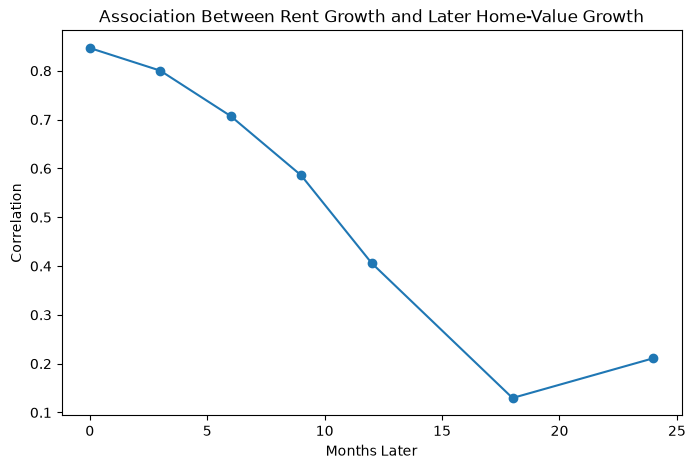

In [40]:
# Plot the correlation between rent growth and future home value growth
plt.figure(figsize=(8, 5))
plt.plot(
    lag_table["lag_months"],
    lag_table["correlation"],
    marker="o"
)
plt.title("Association Between Rent Growth and Later Home-Value Growth")
plt.xlabel("Months Later")
plt.ylabel("Correlation")
plt.show()

**Interpretation of Rent Growth vs. Future Home Value Growth**

The chart shows a strong positive correlation between rent growth and home value growth, with the relationship weakening as the time lag increases. The correlation is approximately 0.85 at lag 0, indicating a strong positive association between rent growth and home value growth in the same month. It decreases to around 0.80 at 3 months, 0.71 at 6 months, and 0.59 at 9 months.

At a 12-month lag, the correlation falls to approximately 0.41, and it reaches its lowest point of about 0.13 at 18 months. At 24 months, it rises slightly to approximately 0.21, but the relationship remains relatively weak compared with shorter lags.

Overall, the results suggest that rent growth is more strongly associated with home value growth over shorter time horizons, while the association becomes weaker at longer lags. The relatively high same-month correlation does not establish that rent growth predicts future home value growth, and the declining correlations suggest limited evidence of a strong long-term relationship in this analysis.

In [41]:
from sklearn.linear_model import LinearRegression
# Get home value growth 12 months into the future for each metro
future_price_growth = (
    panel.groupby("RegionID")["zhvi_yoy"]
    .shift(-12)
)
# Create the regression dataset
regression_data = pd.DataFrame({
    "rent_growth": panel["zori_yoy"],
    "future_price_growth": future_price_growth
})
# Remove rows with missing values
regression_data = regression_data.dropna()
regression_data.head()

,rent_growth,future_price_growth
12,7.836443,8.883396
13,8.803636,9.022900
14,8.184930,9.400364
15,8.180830,9.598987
16,8.560263,9.478382


**Fit a Linear Regression Model**

Fit a simple linear regression model to examine the relationship between current rent growth and home value growth 12 months later.

The model uses **rent growth as the independent variable (\(X\))** and **future home value growth as the dependent variable (\(y\))**. After fitting the model, extract the intercept, slope, and $R^2$ score to evaluate the estimated relationship and the model's explanatory power.

In [42]:
# Define the independent and dependent variables
X = regression_data[["rent_growth"]]
y = regression_data["future_price_growth"]
# Fit the linear regression model
model = LinearRegression()
model.fit(X, y)
# Extract model parameters and goodness of fit
slope = model.coef_[0]
intercept = model.intercept_
r_squared = model.score(X, y)
# Display the results
print("Intercept:", round(intercept, 2))
print("Slope:", round(slope, 2))
print("R-squared:", round(r_squared, 3))

Intercept: 1.35
Slope: 0.54
R-squared: 0.165


**Interpretation of Linear Regression Results**

The regression model produces an intercept of **1.35**, a slope of **0.54**, and an $R^2$ of **0.165**.

The positive slope indicates that a 1-percentage-point increase in current rent growth is associated with a 0.54-percentage-point increase in home value growth 12 months later, on average. This suggests a positive relationship between rent growth and future home value growth.

However, the $R^2$ value of 0.165 indicates that the model explains approximately **16.5% of the variation** in future home value growth. Therefore, rent growth alone has limited explanatory power in this linear model, and other factors likely contribute to differences in home value growth across metropolitan areas.

Overall, the results suggest a positive association between rent growth and home value growth one year later, but rent growth alone does not explain most of the variation in future home value growth. These findings indicate association rather than causation.

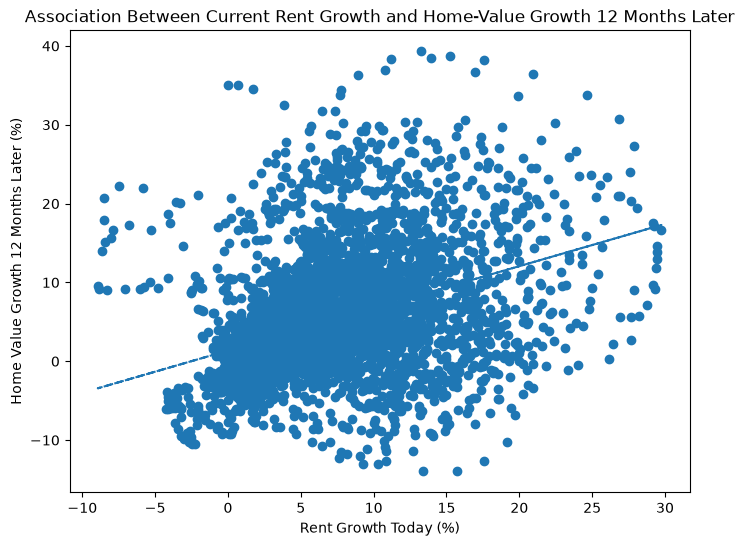

In [43]:
# Generate predicted future home value growth
predicted = model.predict(X)
# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    regression_data["rent_growth"],
    regression_data["future_price_growth"]
)
plt.plot(
    regression_data["rent_growth"],
    predicted,
    "--"
)
plt.title(
    "Association Between Current Rent Growth and Home-Value Growth 12 Months Later"
)
plt.xlabel("Rent Growth Today (%)")
plt.ylabel(
    "Home Value Growth 12 Months Later (%)"
)
plt.show()

**Interpretation of Rent Growth vs. Home Value Growth 12 Months Later**

The scatter plot shows a positive relationship between current rent growth and home value growth 12 months later, consistent with the regression slope of 0.54. However, the points are widely dispersed around the regression line, indicating substantial variation in future home value growth that is not explained by rent growth alone.

The fitted line slopes upward, suggesting that higher rent growth is associated with higher home value growth one year later, on average. Nevertheless, observations with similar rent growth often have very different future home value growth rates, and some metros experience negative home value growth despite positive rent growth.

This finding is consistent with the model's $R^2$ of 0.165, which indicates that rent growth alone explains approximately 16.5% of the variation in future home value growth in the sample.

Overall, the chart supports a positive but limited linear association between rent growth and home value growth 12 months later. Other factors likely contribute to differences in housing market performance across metropolitan areas, and the relationship should not be interpreted as evidence of causation.

**Determine the Optimal Number of Clusters Using the Elbow Method**

Use K-means clustering to group metropolitan areas based on cumulative home value growth and rent growth from January 2020 to August 2026. Before clustering, standardize both variables using `StandardScaler` so that they contribute comparably to the distance calculations.

The elbow method evaluates different numbers of clusters (\(k\)) by calculating inertia, which measures the sum of squared distances between observations and their assigned cluster centers. Plotting inertia against the number of clusters helps identify an elbow point where adding more clusters produces diminishing improvements.

The selected number of clusters will be used to group metropolitan areas with similar housing market growth patterns.

C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.p

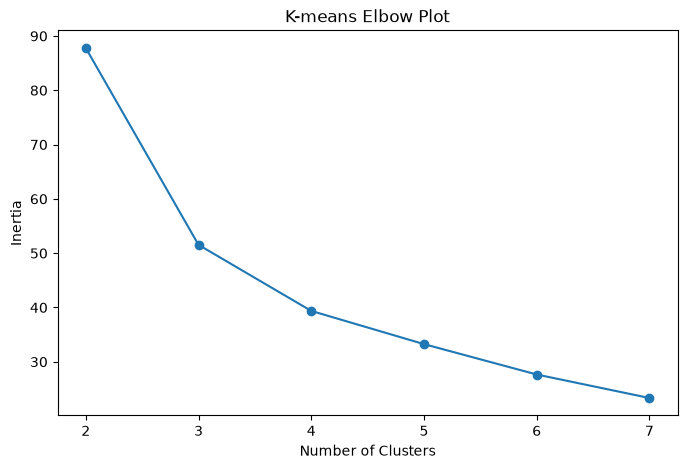

In [44]:
# Select home value growth and rent growth as clustering features
X = summary[
    ["price_growth", "rent_growth"]
]
# Standardize the features before clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Store inertia values for different numbers of clusters
inertia = []
# Test cluster counts from 2 to 7
for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)
# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 8),
    inertia,
    marker="o"
)
plt.title("K-means Elbow Plot")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

**Interpretation of the K-means Elbow Plot**

The elbow plot shows that inertia decreases substantially as the number of clusters increases from 2 to 3, then continues to decline more gradually. The largest reduction occurs between \(k=2\) and \(k=3\), while the improvement becomes smaller for additional clusters.

Based on this pattern, **\(k=3\) appears to be a reasonable choice** for the K-means clustering analysis. Three clusters may provide a useful balance between capturing differences in home value and rent growth across metropolitan areas and keeping the groups relatively simple to interpret.

In the next step, K-means clustering can be performed with three clusters to identify groups of metros with similar housing market growth patterns. The resulting clusters should then be examined to understand how their home value growth and rent growth differ.

**Perform K-means Clustering and Summarize Results**

Apply K-means clustering with three clusters to group metropolitan areas based on their cumulative home value growth and rent growth from January 2020 to August 2026. The standardized features (`X_scaled`) ensure that both variables contribute comparably to the clustering process.

After assigning each metro to a cluster, calculate the average home value growth, rent growth, and growth divergence within each group. These averages help characterize the housing market patterns associated with each cluster.

The results can reveal groups of metros where home values and rents grew at different rates, providing a clearer understanding of variation in housing market dynamics across metropolitan areas.

In [45]:
# Set the number of clusters based on the elbow plot
k = 3
# Initialize the K-means model
model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
# Assign each metro to a cluster
summary["cluster"] = model.fit_predict(X_scaled)
# Calculate average growth metrics for each cluster
cluster_summary = summary.groupby("cluster")[
    [
        "price_growth",
        "rent_growth",
        "divergence"
    ]
].mean()
# Display the cluster-level averages
cluster_summary

C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,price_growth,rent_growth,divergence
cluster,,,
0,58.297366,52.779928,5.517437
1,30.620852,28.115512,2.505341
2,47.820436,40.271893,7.548542


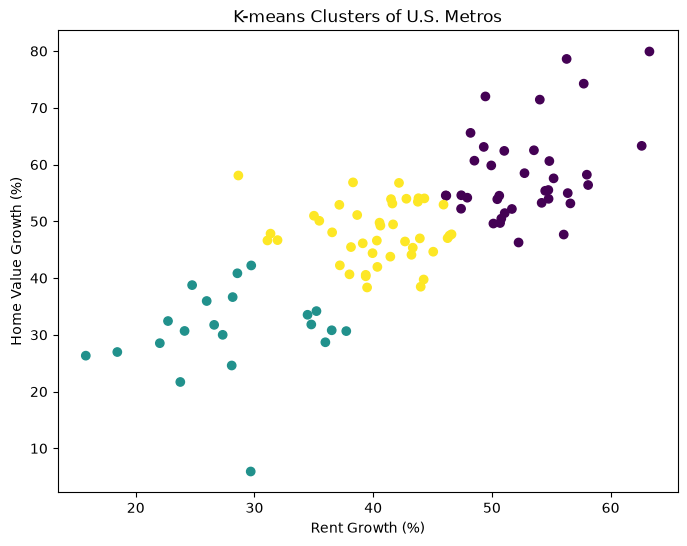

In [46]:
# Count the number of metros in each cluster
summary["cluster"].value_counts().sort_index()
# Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    summary["rent_growth"],
    summary["price_growth"],
    c=summary["cluster"]
)
plt.title("K-means Clusters of U.S. Metros")
plt.xlabel("Rent Growth (%)")
plt.ylabel("Home Value Growth (%)")
plt.show()

**Interpretation of K-means Clusters Across U.S. Metropolitan Areas**

The scatter plot identifies three distinct groups of metropolitan areas based on cumulative home value growth and rent growth from January 2020 to August 2026.

- **Cluster 0 (teal): Lower growth markets.** These metros generally experienced lower rent growth and home value growth than the other groups. Most observations have home value growth below 40%, with one notable outlier showing particularly low home value growth.
- **Cluster 1 (yellow): Moderate growth markets.** These metros generally experienced moderate-to-high growth in both home values and rents, with home value growth mostly around 40–58% and rent growth around 30–47%.
- **Cluster 2 (purple): Higher growth markets.** These metros generally experienced higher growth in both variables, with rent growth mostly around 47–60% and home value growth frequently exceeding 50%. Several metros experienced home value growth above 70%.

Overall, the clustering reveals meaningful variation in housing market growth across metropolitan areas. The groups range from relatively lower-growth markets to markets with stronger appreciation in both home values and rents. However, because the clustering uses only these two growth variables, it does not directly measure housing affordability or explain the underlying causes of these differences.

In [47]:
# Display growth metrics and cluster assignments for each metro
summary[
    [
        "RegionName",
        "price_growth",
        "rent_growth",
        "divergence",
        "cluster"
    ]
].sort_values("cluster")

,RegionName,price_growth,rent_growth,divergence,cluster
0,"Akron, OH",56.394705,58.105990,-1.711284,0
2,"Albuquerque, NM",62.519063,53.541901,8.977162,0
3,"Allentown, PA",62.410325,51.042428,11.367897,0
5,"Augusta, GA",52.174571,51.684808,0.489763,0
7,"Bakersfield, CA",53.154363,56.611664,-3.457301,0
...,...,...,...,...,...
65,"Philadelphia, PA",52.905462,37.149648,15.755814,2
94,"Wichita, KS",54.069675,43.814053,10.255622,2
90,"Tucson, AZ",44.099842,43.225482,0.874360,2
85,"St. Louis, MO",47.711679,46.599593,1.112085,2
